# CuPy numerical libraries: dense matrix multiplication

Compute $C=AB$ for rectangular dense matrices. Compare all entries with NumPy, check selected entries as row-column dot products, and display the matrices and errors. The GPU product uses a library routine rather than a hand-written CUDA kernel.

Run cells in order in a Google Colab GPU runtime. All figures and printouts stay in the notebook; no result files are exported. This is an introductory correctness experiment, not a CPU/GPU speed benchmark.

## 1. Prepare Colab

Select **Runtime → Change runtime type → GPU**. The checks inspect the remote Linux runtime. The toolkit version selects the binary package only if CuPy is absent; an existing installation is retained.

In [1]:
!nvidia-smi
!nvcc --version

Sun Oct 18 07:10:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Use the existing CuPy installation when available. The next cell installs a CUDA-specific binary package **only if CuPy is absent**, selecting CUDA 12 or 13 from the installed toolkit. It does not install PyCUDA or a notebook extension. Do not install multiple CuPy packages in the same environment.

If an existing CuPy installation fails to import, use a fresh Colab GPU runtime before proceeding. For other environments, follow the [CuPy installation guide](https://docs.cupy.dev/en/stable/install.html).

In [2]:
import importlib.util
import re
import subprocess
import sys

if importlib.util.find_spec("cupy") is None:
    toolkit_info = subprocess.check_output(
        ["nvcc", "--version"], text=True
    )
    match = re.search(r"release\s+(\d+)\.", toolkit_info)
    if match is None or int(match.group(1)) not in (12, 13):
        raise RuntimeError("Use a Colab GPU runtime with CUDA 12 or 13, or follow the CuPy installation guide.")
    package = f"cupy-cuda{match.group(1)}x"
    subprocess.check_call([sys.executable, "-m", "pip", "install", package])
    print("Installed:", package)
else:
    print("Using the existing CuPy installation.")

Using the existing CuPy installation.


## 2. Imports and validation

Double precision makes the numerical comparisons easier to interpret. Inputs are identical for CPU and GPU; floating-point results are compared with tolerances, not required to match bit for bit. CuPy does not use the CPU as a fallback in this notebook.

In [3]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import cupy as cp

if cp.cuda.runtime.getDeviceCount() < 1:
    raise RuntimeError("Select a GPU runtime in Colab.")
cp.cuda.Device(0).use()
name = cp.cuda.runtime.getDeviceProperties(0)["name"]
if isinstance(name, bytes):
    name = name.decode()
print("GPU:", name)
print("Python:", sys.version.split()[0], "NumPy:", np.__version__, "CuPy:", cp.__version__)
plt.rcParams.update({'figure.dpi':120, 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False})

GPU: Tesla T4
Python: 3.13.15 NumPy: 2.1.3 CuPy: 14.0.1


In [4]:
def check(label, result, reference, rtol=1e-11, atol=1e-11):
    assert result.shape == reference.shape, (result.shape, reference.shape)
    assert result.dtype == reference.dtype, (result.dtype, reference.dtype)
    if not np.all(np.isfinite(result)):
        raise AssertionError(f"{label}: nonfinite result")
    np.testing.assert_allclose(result, reference, rtol=rtol, atol=atol)
    error = np.max(np.abs(result-reference))
    relative = np.linalg.norm((result-reference).ravel()) / max(np.linalg.norm(reference.ravel()), np.finfo(float).tiny)
    print(f"{label}: validated; max absolute error={error:.3e}; relative norm error={relative:.3e}")

## 3. Prepare compatible rectangular matrices

Choose $A\in\mathbb{R}^{96\times64}$ and $B\in\mathbb{R}^{64\times80}$, giving $C\in\mathbb{R}^{96\times80}$. The deterministic formulas create visible structure without identical rows or columns. The shared inner dimension, 64, is the length of each dot product.

In [5]:
M, K, P = 96, 64, 80
r = np.arange(M,dtype=np.float64)[:,None]
k = np.arange(K,dtype=np.float64)[None,:]
h_A = np.sin(0.07*(r+1)*(k+1)) + 0.1*np.cos(0.19*r)
k_col = np.arange(K,dtype=np.float64)[:,None]
p = np.arange(P,dtype=np.float64)[None,:]
h_B = np.cos(0.05*(k_col+1)*(p+1)) + 0.2*np.sin(0.13*p)
h_A = np.ascontiguousarray(h_A)
h_B = np.ascontiguousarray(h_B)
C_cpu = h_A @ h_B
print("A:",h_A.shape,"B:",h_B.shape,"C:",C_cpu.shape)
print("Input dtypes:",h_A.dtype,h_B.dtype)

A: (96, 64) B: (64, 80) C: (96, 80)
Input dtypes: float64 float64


## 4. Compute the dense product

For two-dimensional dense arrays, `@` and `cp.matmul` express matrix multiplication. In contrast, `*` performs elementwise multiplication and is not a substitute. CuPy manages the underlying numerical-library call.

Transfer inputs once; the output remains on the device until retrieved. There is no user-selected grid or block size.

In [6]:
d_A = cp.asarray(h_A)
d_B = cp.asarray(h_B)
d_C = cp.matmul(d_A, d_B)
C_gpu = cp.asnumpy(d_C)
check("Dense matrix product", C_gpu, C_cpu,rtol=2e-11,atol=2e-11)

# An independent explicit dot product verifies selected output entries.
selected_entries = [(0,0),(M//2,P//2),(M-1,P-1)]
print(f"{'(row,col)':>14} {'GPU':>20} {'NumPy':>20} {'explicit dot':>20}")
for i,j in selected_entries:
    explicit_dot = sum(float(h_A[i,l])*float(h_B[l,j]) for l in range(K))
    np.testing.assert_allclose(C_gpu[i,j],explicit_dot,rtol=2e-11,atol=2e-11)
    print(f"{str((i,j)):>14} {C_gpu[i,j]:20.12f} {C_cpu[i,j]:20.12f} {explicit_dot:20.12f}")

Dense matrix product: validated; max absolute error=0.000e+00; relative norm error=0.000e+00
     (row,col)                  GPU                NumPy         explicit dot
        (0, 0)      21.541875833686      21.541875833686      21.541875833686
      (48, 40)       0.682707560535       0.682707560535       0.682707560535
      (95, 79)      -1.429266973463      -1.429266973463      -1.429266973463


## 5. Visualize the matrices and product error

Every pixel represents a matrix entry. A and B use a common color scale; the product has its own scale because it sums many products. The final panel shows the absolute difference from NumPy.

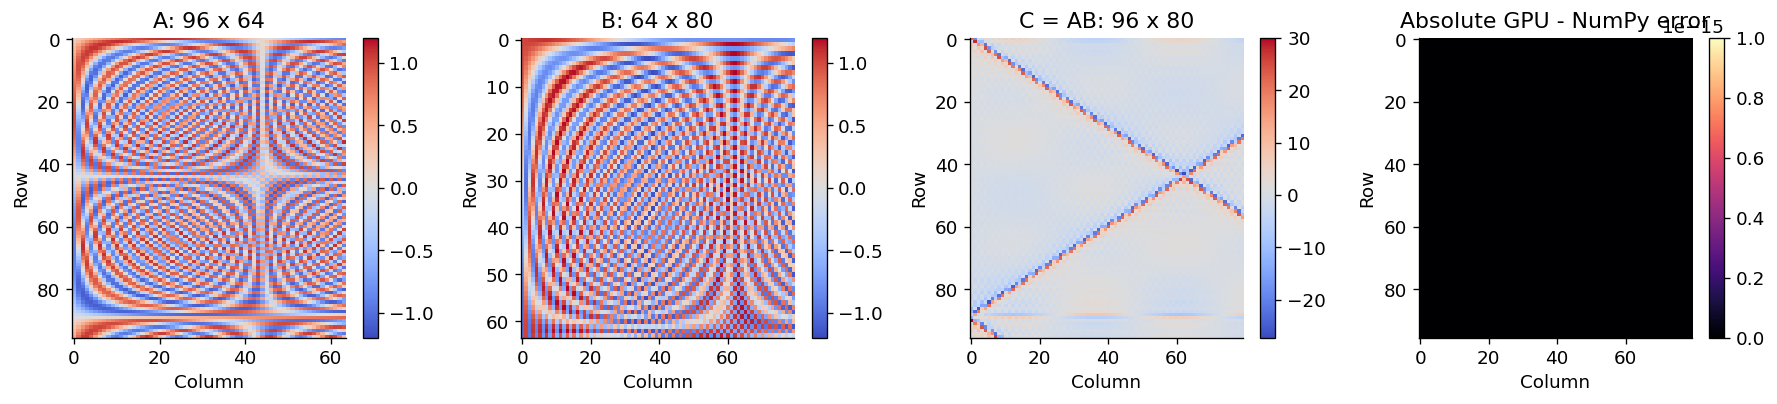

In [7]:
fig, axes=plt.subplots(1,4,figsize=(15,3.5))
limit=max(np.max(np.abs(h_A)),np.max(np.abs(h_B)))
for ax,matrix,title in zip(axes[:2],[h_A,h_B],[f'A: {M} x {K}',f'B: {K} x {P}']):
    im=ax.imshow(matrix,cmap='coolwarm',vmin=-limit,vmax=limit,aspect='auto')
    ax.set(title=title,xlabel='Column',ylabel='Row');fig.colorbar(im,ax=ax)
im=axes[2].imshow(C_gpu,cmap='coolwarm',aspect='auto')
axes[2].set(title=f'C = AB: {M} x {P}',xlabel='Column',ylabel='Row');fig.colorbar(im,ax=axes[2])
error = np.abs(C_gpu-C_cpu)
im=axes[3].imshow(error,cmap='magma',aspect='auto',vmin=0,
                  vmax=max(float(error.max()),1e-15))
axes[3].set(title='Absolute GPU - NumPy error',xlabel='Column',ylabel='Row');fig.colorbar(im,ax=axes[3])
fig.tight_layout();plt.show()

## 6. A small example: matrix versus elementwise multiplication

Use square arrays so that both operations are legal. The different answers make the distinction visible. For C=AB, each output is a row-column dot product; elementwise multiplication uses only the two entries at the same location.

In [8]:
small_A = np.array([[1.,2.],[3.,4.]],dtype=np.float64)
small_B = np.array([[5.,6.],[7.,8.]],dtype=np.float64)
ds_A, ds_B = cp.asarray(small_A), cp.asarray(small_B)
small_matmul = cp.asnumpy(ds_A @ ds_B)
small_elementwise = cp.asnumpy(ds_A * ds_B)
check("Small matrix product",small_matmul,np.array([[19.,22.],[43.,50.]]))
check("Small elementwise product",small_elementwise,np.array([[5.,12.],[21.,32.]]))
print("A @ B (matrix product):\n",small_matmul)
print("A * B (elementwise product):\n",small_elementwise)

Small matrix product: validated; max absolute error=0.000e+00; relative norm error=0.000e+00
Small elementwise product: validated; max absolute error=0.000e+00; relative norm error=0.000e+00
A @ B (matrix product):
 [[19. 22.]
 [43. 50.]]
A * B (elementwise product):
 [[ 5. 12.]
 [21. 32.]]


## Interpretation and execution status

Inputs and intermediate results stay on the device until explicitly retrieved for checking or plotting. These small examples establish correctness and illustrate the interface; they do not establish a speedup. Any later performance study must state transfer, allocation, and initialization costs.

**Preparation status:** delivered with empty outputs. Python syntax, mathematical checks, CPU reference calculations, and plot rendering were checked. GPU compilation and execution were unavailable during preparation; run on Colab for actual GPU results.

References: [cupy.matmul](https://docs.cupy.dev/en/stable/reference/generated/cupy.matmul.html).

## Cleanup

After completing the examples, remove device-array references. CuPy may keep freed blocks in its memory pool. Rerun from data preparation before computing again.

In [9]:
cp.cuda.get_current_stream().synchronize()
del d_A, d_B, d_C, ds_A, ds_B
print("Device array references released.")

Device array references released.
